# Lab 6 — Language Identification using FastText Word Vectors

## 1. Setup — install packages

Run this once. On Windows, if `pip install fasttext` fails to build, use `pip install fasttext-wheel` instead.

In [ ]:
  # Uncomment the lines below if these packages are not already installed
!pip install matplotlib torch
!pip install -U pip
!pip uninstall -y fasttext fasttext-wheel -q
!pip install -q fasttext



  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Imports

In [ ]:
import os
import re
import random
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


In [ ]:
# --- Compatibility patch: the `fasttext` library internally calls
# `np.array(obj, copy=False)`, which NumPy 2.x raises a ValueError on when a
# copy is actually required (NumPy 1.x silently allowed it). This patches
# `np.array` so copy=False behaves like NumPy 1.x (copy if needed, no error).
# Safe no-op if you're already on NumPy < 2.0.
_np_major_version = int(np.__version__.split(".")[0])
if _np_major_version >= 2:
    _orig_np_array = np.array
    def _np_array_compat(*args, **kwargs):
        if kwargs.get("copy", "unset") is False:
            kwargs["copy"] = None  # None = "copy only if needed", NumPy 1.x behaviour
        return _orig_np_array(*args, **kwargs)
    np.array = _np_array_compat
    print(f"[compat] Patched np.array for NumPy {np.__version__} <-> fasttext compatibility")

import fasttext

[compat] Patched np.array for NumPy 2.1.3 <-> fasttext compatibility


## 3. Configuration — paths, language mapping, hyperparameters

In [ ]:
# ---- Paths ----
RAW_DATA_DIR = r"/content/drive/MyDrive/ILLM_LAB_1"
OUTPUT_DIR = r"/content/drive/MyDrive/ILLM_LAB_6"
FASTTEXT_VEC_DIR = os.path.join(OUTPUT_DIR, "fasttext_vectors")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FASTTEXT_VEC_DIR, exist_ok=True)

# ---- Language mapping (from Assignment 1) ----
language_mapping = {
    "as.txt": "Assamese",
    "bd.txt": "Bodo",
    "bn.txt": "Bengali",
    "dg.txt": "Dogri",
    "en.txt": "English",
    "gom.txt": "Goan Konkani",
    "gu.txt": "Gujarati",
    "hi.txt": "Hindi",
    "kha.txt": "Khasi",
    "kn.txt": "Kannada",
    "ks.txt": "Kashmiri",
    "mai.txt": "Maithili",
    "ml.txt": "Malayalam",
    "mni.txt": "Manipuri (Meitei)",
    "mr.txt": "Marathi",
    "ne.txt": "Nepali",
    "or.txt": "Odia",
    "pa.txt": "Punjabi",
    "sa.txt": "Sanskrit",
    "sat.txt": "Santali",
    "sd.txt": "Sindhi",
    "ta.txt": "Tamil",
    "te.txt": "Telugu",
    "ur.txt": "Urdu",
}

# ---- Hyperparameters (tune as needed) ----
MAX_SAMPLES_PER_LANG = 2000   # cap per language for speed; set to None to use ALL lines
MIN_SENTENCE_LEN_CHARS = 3
EMBED_DIM = 50
MAX_SEQ_LEN = 25              # max tokens per sentence for LSTM/GRU
MLP_HIDDEN_DIM = 128
RNN_HIDDEN_DIM = 128
BATCH_SIZE = 64

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cpu


## 4. Load raw data

Each line in a language's `.txt` file is treated as one text sample.

In [ ]:
def load_raw_data(raw_dir, lang_map, max_per_lang=None, min_len=3):
    rows = []
    for fname, lang in lang_map.items():
        fpath = os.path.join(raw_dir, fname)
        if not os.path.exists(fpath):
            print(f"[WARN] missing file, skipping: {fpath}")
            continue
        with open(fpath, "r", encoding="utf-8", errors="ignore") as f:
            lines = [ln.strip() for ln in f if len(ln.strip()) >= min_len]
        if max_per_lang is not None and len(lines) > max_per_lang:
            random.shuffle(lines)
            lines = lines[:max_per_lang]
        lang_code = fname.replace(".txt", "")
        for ln in lines:
            rows.append({"text": ln, "label": lang, "lang_code": lang_code})
    return pd.DataFrame(rows)

df = load_raw_data(RAW_DATA_DIR, language_mapping, MAX_SAMPLES_PER_LANG, MIN_SENTENCE_LEN_CHARS)
print("Total samples:", len(df))
print(df["label"].value_counts())

df.to_csv(os.path.join(OUTPUT_DIR, "combined_dataset.csv"), index=False, encoding="utf-8-sig")


Total samples: 48000
label
Assamese             2000
Bodo                 2000
Bengali              2000
Dogri                2000
English              2000
Goan Konkani         2000
Gujarati             2000
Hindi                2000
Khasi                2000
Kannada              2000
Kashmiri             2000
Maithili             2000
Malayalam            2000
Manipuri (Meitei)    2000
Marathi              2000
Nepali               2000
Odia                 2000
Punjabi              2000
Sanskrit             2000
Santali              2000
Sindhi               2000
Tamil                2000
Telugu               2000
Urdu                 2000
Name: count, dtype: int64


## 5. Train / Validation / Test split (manual, stratified)

Implemented from scratch (no `sklearn.model_selection`) so class proportions are preserved per language.

In [ ]:
def stratified_split(dframe, label_col="label", train_frac=0.8, val_frac=0.1, seed=SEED):
    rng = np.random.RandomState(seed)
    train_idx, val_idx, test_idx = [], [], []
    for _, group in dframe.groupby(label_col):
        idx = group.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        n_train = int(n * train_frac)
        n_val = int(n * val_frac)
        train_idx.extend(idx[:n_train])
        val_idx.extend(idx[n_train:n_train + n_val])
        test_idx.extend(idx[n_train + n_val:])
    return (dframe.loc[train_idx].reset_index(drop=True),
            dframe.loc[val_idx].reset_index(drop=True),
            dframe.loc[test_idx].reset_index(drop=True))

train_df, val_df, test_df = stratified_split(df)
print("train:", len(train_df), " val:", len(val_df), " test:", len(test_df))

train_df.to_csv(os.path.join(OUTPUT_DIR, "train.csv"), index=False, encoding="utf-8-sig")
val_df.to_csv(os.path.join(OUTPUT_DIR, "val.csv"), index=False, encoding="utf-8-sig")
test_df.to_csv(os.path.join(OUTPUT_DIR, "test.csv"), index=False, encoding="utf-8-sig")

classes = sorted(df["label"].unique().tolist())
label2idx = {l: i for i, l in enumerate(classes)}
idx2label = {i: l for l, i in label2idx.items()}
print("Num classes:", len(classes))


train: 38400  val: 4800  test: 4800
Num classes: 24


## 6. Tokenizer

In [ ]:
TOKEN_RE = re.compile(r"\w+", re.UNICODE)

def tokenize(text):
    return TOKEN_RE.findall(text.lower())


## 7. FastText word vectors

Loads pretrained `.vec` files if present in `FASTTEXT_VEC_DIR`; otherwise trains a small custom FastText skip-gram model per language as a fallback so the notebook always runs end-to-end.

In [ ]:
def load_vec_file(path, expected_dim=EMBED_DIM):
    vectors = {}

    with open(path, "r", encoding="utf-8", newline="\n", errors="ignore") as f:
        first_line = f.readline()
        parts = first_line.split()

        # If there is no "vocab_size dimension" header, rewind
        if len(parts) != 2:
            f.seek(0)

        for line in f:
            tokens = line.rstrip().split()

            if len(tokens) < expected_dim + 1:
                continue

            word = tokens[0]

            try:
                vec = np.asarray(
                    tokens[1:expected_dim + 1],
                    dtype="float32"
                )
            except ValueError:
                continue

            if len(vec) != expected_dim:
                continue

            vectors[word] = vec

    return vectors


def find_pretrained_vec_file(lang_code, vec_dir):
    candidates = [
        f"custom_fasttext_{lang_code}.bin",
        f"cc.{lang_code}.300.vec",
        f"wiki.{lang_code}.vec",
        f"wiki.{lang_code}.align.vec",
    ]

    for filename in candidates:
        path = os.path.join(vec_dir, filename)

        if os.path.isfile(path):
            return path

    return None


def get_language_vectors(
    lang_code,
    lang_texts,
    vec_dir,
    embed_dim=EMBED_DIM,
    max_vocab_for_custom=20000
):
    vec_path = find_pretrained_vec_file(lang_code, vec_dir)

    if vec_path is not None:
        print(f"[{lang_code}] Loading pretrained FastText vectors from {vec_path}")

        # .bin = FastText binary model
        if vec_path.endswith(".bin"):
            model = fasttext.load_model(vec_path)

            words = model.get_words()[:max_vocab_for_custom]

            vectors = {
                word: model.get_word_vector(word)
                for word in words
            }

            return vectors

        # .vec = text vectors
        return load_vec_file(vec_path, embed_dim)

    print(
        f"[{lang_code}] No pretrained vectors found in {vec_dir} "
        "-> training a custom FastText skip-gram model on this language's corpus."
    )

    os.makedirs(vec_dir, exist_ok=True)

    corpus_path = os.path.join(
        vec_dir,
        f"_corpus_{lang_code}.txt"
    )

    with open(corpus_path, "w", encoding="utf-8") as f:
        for t in lang_texts:
            f.write(t + "\n")

    model = fasttext.train_unsupervised(
        corpus_path,
        model="skipgram",
        dim=embed_dim,
        minCount=1,
        epoch=10
    )

    words = model.get_words()[:max_vocab_for_custom]

    vectors = {
        word: model.get_word_vector(word)
        for word in words
    }

    model.save_model(
        os.path.join(
            vec_dir,
            f"custom_fasttext_{lang_code}.bin"
        )
    )

    return vectors

lang_vectors = {}
for fname, lang in language_mapping.items():
    lang_code = fname.replace(".txt", "")
    lang_texts = df.loc[df["lang_code"] == lang_code, "text"].tolist()
    if len(lang_texts) == 0:
        continue
    lang_vectors[lang_code] = get_language_vectors(lang_code, lang_texts, FASTTEXT_VEC_DIR)

# Merge all per-language vectors into one lookup table used everywhere below
combined_word_vectors = {}
for lang_code, vecs in lang_vectors.items():
    combined_word_vectors.update(vecs)
print("Total unique words with vectors:", len(combined_word_vectors))

[as] Loading pretrained FastText vectors from /content/drive/MyDrive/ILLM_LAB_6/fasttext_vectors/custom_fasttext_as.bin
[bd] Loading pretrained FastText vectors from /content/drive/MyDrive/ILLM_LAB_6/fasttext_vectors/custom_fasttext_bd.bin
[bn] Loading pretrained FastText vectors from /content/drive/MyDrive/ILLM_LAB_6/fasttext_vectors/custom_fasttext_bn.bin
[dg] Loading pretrained FastText vectors from /content/drive/MyDrive/ILLM_LAB_6/fasttext_vectors/custom_fasttext_dg.bin
[en] Loading pretrained FastText vectors from /content/drive/MyDrive/ILLM_LAB_6/fasttext_vectors/custom_fasttext_en.bin
[gom] Loading pretrained FastText vectors from /content/drive/MyDrive/ILLM_LAB_6/fasttext_vectors/custom_fasttext_gom.bin
[gu] Loading pretrained FastText vectors from /content/drive/MyDrive/ILLM_LAB_6/fasttext_vectors/custom_fasttext_gu.bin
[hi] Loading pretrained FastText vectors from /content/drive/MyDrive/ILLM_LAB_6/fasttext_vectors/custom_fasttext_hi.bin
[kha] Loading pretrained FastText vect

## 8. Averaged sentence vectors (features for Logistic Regression & MLP)

In [ ]:
def sentence_to_avg_vector(text, word_vectors, dim=EMBED_DIM):
    tokens = tokenize(text)
    vecs = [word_vectors[t] for t in tokens if t in word_vectors]
    if len(vecs) == 0:
        return np.zeros(dim, dtype="float32")
    return np.mean(vecs, axis=0)

def build_avg_matrix(dframe, word_vectors):
    X = np.stack([sentence_to_avg_vector(t, word_vectors) for t in dframe["text"]]).astype("float32")
    y = np.array([label2idx[l] for l in dframe["label"]], dtype="int64")
    return X, y

X_train_avg, y_train = build_avg_matrix(train_df, combined_word_vectors)
X_val_avg, y_val = build_avg_matrix(val_df, combined_word_vectors)
X_test_avg, y_test = build_avg_matrix(test_df, combined_word_vectors)
print(X_train_avg.shape, X_val_avg.shape, X_test_avg.shape)


(38400, 50) (4800, 50) (4800, 50)


## 9. Manual evaluation metric — Macro-F1

Computed entirely from scratch (true positives / false positives / false negatives per class). No `sklearn.metrics` used.

In [ ]:
def macro_f1_score(y_true, y_pred, num_classes):
    tp = np.zeros(num_classes)
    fp = np.zeros(num_classes)
    fn = np.zeros(num_classes)
    for t, p in zip(y_true, y_pred):
        if t == p:
            tp[t] += 1
        else:
            fp[p] += 1
            fn[t] += 1

    precisions, recalls, f1s = [], [], []
    for c in range(num_classes):
        prec = tp[c] / (tp[c] + fp[c]) if (tp[c] + fp[c]) > 0 else 0.0
        rec = tp[c] / (tp[c] + fn[c]) if (tp[c] + fn[c]) > 0 else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        precisions.append(prec); recalls.append(rec); f1s.append(f1)

    macro_f1 = float(np.mean(f1s))
    per_class = {idx2label[c]: {"precision": precisions[c], "recall": recalls[c], "f1": f1s[c]}
                 for c in range(num_classes)}
    return macro_f1, per_class

def print_report(name, macro_f1, per_class):
    print(f"\n=== {name} — Macro-F1: {macro_f1:.4f} ===")
    for lang, m in per_class.items():
        print(f"  {lang:20s} P={m['precision']:.3f}  R={m['recall']:.3f}  F1={m['f1']:.3f}")

results = {}


## 10. Model 1 — Logistic Regression on averaged FastText vectors

Implemented **from scratch with NumPy** (no `sklearn`): this is multinomial
(softmax) logistic regression, trained with mini-batch gradient descent on
the cross-entropy loss, with a small L2 penalty for regularisation.

In [ ]:
class LogisticRegressionScratch:

    def __init__(self, input_dim, num_classes, lr=0.5, epochs=200, batch_size=128, l2=1e-4, seed=SEED):
        rng = np.random.RandomState(seed)
        self.W = rng.normal(scale=0.01, size=(input_dim, num_classes)).astype("float64")
        self.b = np.zeros(num_classes, dtype="float64")
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.num_classes = num_classes

    @staticmethod
    def _softmax(z):
        z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def fit(self, X, y, X_val=None, y_val=None, verbose_every=20):
        X = X.astype("float64")
        n = X.shape[0]
        y_onehot = np.zeros((n, self.num_classes))
        y_onehot[np.arange(n), y] = 1.0

        for epoch in range(self.epochs):
            perm = np.random.permutation(n)
            X_shuf, y_shuf = X[perm], y_onehot[perm]
            for start in range(0, n, self.batch_size):
                xb = X_shuf[start:start + self.batch_size]
                yb = y_shuf[start:start + self.batch_size]
                logits = xb @ self.W + self.b
                probs = self._softmax(logits)
                grad_logits = (probs - yb) / xb.shape[0]
                grad_W = xb.T @ grad_logits + self.l2 * self.W
                grad_b = grad_logits.sum(axis=0)
                self.W -= self.lr * grad_W
                self.b -= self.lr * grad_b

            if X_val is not None and (epoch + 1) % verbose_every == 0:
                preds = self.predict(X_val)
                val_mf1, _ = macro_f1_score(y_val, preds, self.num_classes)
                print(f"[LogisticRegression-scratch] epoch {epoch+1}/{self.epochs} - val_macroF1={val_mf1:.4f}")
        return self

    def predict_proba(self, X):
        logits = X.astype("float64") @ self.W + self.b
        return self._softmax(logits)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


lr_clf = LogisticRegressionScratch(
    input_dim=EMBED_DIM, num_classes=len(classes),
    lr=0.5, epochs=200, batch_size=128, l2=1e-4,
)
lr_clf.fit(X_train_avg, y_train, X_val_avg, y_val)
y_pred_lr = lr_clf.predict(X_test_avg)

mf1, per_class = macro_f1_score(y_test, y_pred_lr, len(classes))
print_report("Logistic Regression (from scratch, avg FastText vectors)", mf1, per_class)
results["Logistic Regression"] = mf1


[LogisticRegression-scratch] epoch 20/200 - val_macroF1=0.7567
[LogisticRegression-scratch] epoch 40/200 - val_macroF1=0.7617
[LogisticRegression-scratch] epoch 60/200 - val_macroF1=0.7687
[LogisticRegression-scratch] epoch 80/200 - val_macroF1=0.7728
[LogisticRegression-scratch] epoch 100/200 - val_macroF1=0.7684
[LogisticRegression-scratch] epoch 120/200 - val_macroF1=0.7749
[LogisticRegression-scratch] epoch 140/200 - val_macroF1=0.7731
[LogisticRegression-scratch] epoch 160/200 - val_macroF1=0.7729
[LogisticRegression-scratch] epoch 180/200 - val_macroF1=0.7784
[LogisticRegression-scratch] epoch 200/200 - val_macroF1=0.7740

=== Logistic Regression (from scratch, avg FastText vectors) — Macro-F1: 0.7693 ===
  Assamese             P=0.926  R=0.945  F1=0.936
  Bengali              P=0.943  R=0.915  F1=0.929
  Bodo                 P=0.634  R=0.555  F1=0.592
  Dogri                P=0.220  R=0.205  F1=0.212
  English              P=0.840  R=0.735  F1=0.784
  Goan Konkani         P=0.34

## 11. Model 2 — MLP with n = 0, 1, 2 hidden layers (PyTorch)

`n = 0` hidden layers means a single linear layer (input -> output), trained with backprop / cross-entropy — a neural, gradient-trained analogue of the logistic-regression baseline.

In [ ]:
class MLPClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, num_hidden_layers=1):
        super().__init__()
        layers = []
        in_dim = input_dim
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.ReLU())
            in_dim = hidden_dim
        layers.append(nn.Linear(in_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class VecDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def train_torch_model(model, train_ds, val_ds, epochs=15, lr=1e-3, batch_size=BATCH_SIZE, name="model"):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size)

    best_val_f1, best_state = -1.0, None
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            opt.step()
            total_loss += loss.item() * xb.size(0)

        model.eval()
        val_preds, val_true = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                out = model(xb)
                val_preds.extend(out.argmax(dim=1).cpu().numpy())
                val_true.extend(yb.numpy())
        val_mf1, _ = macro_f1_score(val_true, val_preds, len(classes))

        if val_mf1 > best_val_f1:
            best_val_f1 = val_mf1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        print(f"[{name}] epoch {epoch+1}/{epochs} - train_loss={total_loss/len(train_ds):.4f} - val_macroF1={val_mf1:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model


def evaluate_torch_model(model, test_ds, batch_size=BATCH_SIZE):
    model.eval()
    loader = DataLoader(test_ds, batch_size=batch_size)
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            out = model(xb)
            preds.extend(out.argmax(dim=1).cpu().numpy())
            trues.extend(yb.numpy())
    return macro_f1_score(trues, preds, len(classes))


train_ds_avg = VecDataset(X_train_avg, y_train)
val_ds_avg = VecDataset(X_val_avg, y_val)
test_ds_avg = VecDataset(X_test_avg, y_test)

for n_hidden in [0, 1, 2]:
    model = MLPClassifier(EMBED_DIM, hidden_dim=MLP_HIDDEN_DIM, num_classes=len(classes), num_hidden_layers=n_hidden)
    model = train_torch_model(model, train_ds_avg, val_ds_avg, epochs=15, name=f"MLP(n={n_hidden})")
    mf1, per_class = evaluate_torch_model(model, test_ds_avg)
    print_report(f"MLP hidden_layers={n_hidden}", mf1, per_class)
    results[f"MLP (hidden layers={n_hidden})"] = mf1
    torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, f"mlp_hidden{n_hidden}.pt"))


[MLP(n=0)] epoch 1/15 - train_loss=1.9745 - val_macroF1=0.6603
[MLP(n=0)] epoch 2/15 - train_loss=1.0907 - val_macroF1=0.6632
[MLP(n=0)] epoch 3/15 - train_loss=0.9226 - val_macroF1=0.6748
[MLP(n=0)] epoch 4/15 - train_loss=0.8594 - val_macroF1=0.7058
[MLP(n=0)] epoch 5/15 - train_loss=0.8251 - val_macroF1=0.7277
[MLP(n=0)] epoch 6/15 - train_loss=0.8028 - val_macroF1=0.7367
[MLP(n=0)] epoch 7/15 - train_loss=0.7873 - val_macroF1=0.7351
[MLP(n=0)] epoch 8/15 - train_loss=0.7755 - val_macroF1=0.7410
[MLP(n=0)] epoch 9/15 - train_loss=0.7664 - val_macroF1=0.7421
[MLP(n=0)] epoch 10/15 - train_loss=0.7589 - val_macroF1=0.7497
[MLP(n=0)] epoch 11/15 - train_loss=0.7528 - val_macroF1=0.7480
[MLP(n=0)] epoch 12/15 - train_loss=0.7475 - val_macroF1=0.7551
[MLP(n=0)] epoch 13/15 - train_loss=0.7430 - val_macroF1=0.7523
[MLP(n=0)] epoch 14/15 - train_loss=0.7391 - val_macroF1=0.7585
[MLP(n=0)] epoch 15/15 - train_loss=0.7356 - val_macroF1=0.7556

=== MLP hidden_layers=0 — Macro-F1: 0.7581 ===
 

## 12. Sequence data for LSTM / GRU

Build a vocabulary + an embedding matrix initialised from the FastText vectors, then encode every sentence as a padded sequence of token indices.

In [ ]:
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"

def build_vocab(texts, max_vocab=50000):
    counter = Counter()
    for t in texts:
        counter.update(tokenize(t))
    most_common = counter.most_common(max_vocab)
    vocab = [PAD_TOKEN, UNK_TOKEN] + [w for w, _ in most_common]
    return {w: i for i, w in enumerate(vocab)}

word2idx = build_vocab(train_df["text"].tolist())
print("Vocab size:", len(word2idx))

def build_embedding_matrix(word2idx, word_vectors, dim=EMBED_DIM):
    matrix = np.random.normal(scale=0.1, size=(len(word2idx), dim)).astype("float32")
    matrix[word2idx[PAD_TOKEN]] = np.zeros(dim, dtype="float32")
    found = 0
    for w, idx in word2idx.items():
        if w in word_vectors:
            matrix[idx] = word_vectors[w]
            found += 1
    print(f"Initialised {found}/{len(word2idx)} tokens from FastText vectors")
    return matrix

embedding_matrix = build_embedding_matrix(word2idx, combined_word_vectors)

def encode_sequence(text, word2idx, max_len=MAX_SEQ_LEN):
    tokens = tokenize(text)[:max_len]
    ids = [word2idx.get(t, word2idx[UNK_TOKEN]) for t in tokens]
    if len(ids) < max_len:
        ids = ids + [word2idx[PAD_TOKEN]] * (max_len - len(ids))
    return ids

class SeqDataset(Dataset):
    def __init__(self, dframe, word2idx, max_len=MAX_SEQ_LEN):
        self.X = [encode_sequence(t, word2idx, max_len) for t in dframe["text"]]
        self.y = [label2idx[l] for l in dframe["label"]]

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.long), torch.tensor(self.y[idx], dtype=torch.long)

train_ds_seq = SeqDataset(train_df, word2idx)
val_ds_seq = SeqDataset(val_df, word2idx)
test_ds_seq = SeqDataset(test_df, word2idx)


Vocab size: 50002
Initialised 28206/50002 tokens from FastText vectors


## 13. Models 3 & 4 — LSTM and GRU

In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, num_classes, rnn_type="lstm", freeze_embeddings=False):
        super().__init__()
        vocab_size, embed_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=freeze_embeddings,
            padding_idx=0,
        )
        rnn_cls = nn.LSTM if rnn_type.lower() == "lstm" else nn.GRU
        self.rnn = rnn_cls(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        emb = self.embedding(x)
        out, hidden = self.rnn(emb)
        h_n = hidden[0] if isinstance(hidden, tuple) else hidden  # LSTM -> (h_n, c_n)
        return self.fc(h_n[-1])


def train_seq_model(model, train_ds, val_ds, epochs=8, lr=1e-3, batch_size=BATCH_SIZE, name="model"):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size)

    best_val_f1, best_state = -1.0, None
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            opt.step()
            total_loss += loss.item() * xb.size(0)

        model.eval()
        preds, trues = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                out = model(xb)
                preds.extend(out.argmax(dim=1).cpu().numpy())
                trues.extend(yb.numpy())
        val_mf1, _ = macro_f1_score(trues, preds, len(classes))

        if val_mf1 > best_val_f1:
            best_val_f1 = val_mf1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        print(f"[{name}] epoch {epoch+1}/{epochs} - train_loss={total_loss/len(train_ds):.4f} - val_macroF1={val_mf1:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model


lstm_model = RNNClassifier(embedding_matrix, RNN_HIDDEN_DIM, len(classes), rnn_type="lstm")
lstm_model = train_seq_model(lstm_model, train_ds_seq, val_ds_seq, epochs=8, name="LSTM")
mf1, per_class = evaluate_torch_model(lstm_model, test_ds_seq)
print_report("LSTM", mf1, per_class)
results["LSTM"] = mf1
torch.save(lstm_model.state_dict(), os.path.join(OUTPUT_DIR, "lstm_model.pt"))

gru_model = RNNClassifier(embedding_matrix, RNN_HIDDEN_DIM, len(classes), rnn_type="gru")
gru_model = train_seq_model(gru_model, train_ds_seq, val_ds_seq, epochs=8, name="GRU")
mf1, per_class = evaluate_torch_model(gru_model, test_ds_seq)
print_report("GRU", mf1, per_class)
results["GRU"] = mf1
torch.save(gru_model.state_dict(), os.path.join(OUTPUT_DIR, "gru_model.pt"))


[LSTM] epoch 1/8 - train_loss=1.0103 - val_macroF1=0.7363
[LSTM] epoch 2/8 - train_loss=0.5559 - val_macroF1=0.8167
[LSTM] epoch 3/8 - train_loss=0.4093 - val_macroF1=0.8407
[LSTM] epoch 4/8 - train_loss=0.3179 - val_macroF1=0.8531
[LSTM] epoch 5/8 - train_loss=0.2572 - val_macroF1=0.8591
[LSTM] epoch 6/8 - train_loss=0.2172 - val_macroF1=0.8667
[LSTM] epoch 7/8 - train_loss=0.1883 - val_macroF1=0.8680
[LSTM] epoch 8/8 - train_loss=0.1756 - val_macroF1=0.8646

=== LSTM — Macro-F1: 0.8635 ===
  Assamese             P=1.000  R=0.900  F1=0.947
  Bengali              P=0.913  R=1.000  F1=0.955
  Bodo                 P=0.921  R=0.815  F1=0.865
  Dogri                P=0.721  R=0.775  F1=0.747
  English              P=0.667  R=0.570  F1=0.615
  Goan Konkani         P=0.508  R=0.485  F1=0.496
  Gujarati             P=1.000  R=1.000  F1=1.000
  Hindi                P=0.692  R=0.830  F1=0.755
  Kannada              P=0.995  R=1.000  F1=0.998
  Kashmiri             P=0.970  R=0.985  F1=0.978
  K

## 14. Model 5 — FastText supervised classifier

Uses the `fasttext` library's own `train_supervised` on raw text (with `__label__<Language>` prefixes).

In [ ]:
def make_fasttext_file(dframe, path):
    with open(path, "w", encoding="utf-8") as f:
        for _, row in dframe.iterrows():
            label = "__label__" + row["label"].replace(" ", "_")
            text = row["text"].replace("\n", " ")
            f.write(f"{label} {text}\n")

ft_train_path = os.path.join(OUTPUT_DIR, "fasttext_train.txt")
ft_val_path = os.path.join(OUTPUT_DIR, "fasttext_val.txt")
ft_test_path = os.path.join(OUTPUT_DIR, "fasttext_test.txt")
make_fasttext_file(train_df, ft_train_path)
make_fasttext_file(val_df, ft_val_path)
make_fasttext_file(test_df, ft_test_path)

ft_model = fasttext.train_supervised(
    input=ft_train_path,
    epoch=25,
    lr=1.0,
    wordNgrams=2,
    dim=EMBED_DIM,
    loss="softmax",
)
ft_model.save_model(os.path.join(OUTPUT_DIR, "fasttext_supervised_model.bin"))

def evaluate_fasttext(model, dframe):
    y_true_idx, y_pred_idx = [], []
    for _, row in dframe.iterrows():
        text = row["text"].replace("\n", " ")
        pred_label = model.predict(text)[0][0].replace("__label__", "")
        y_true_idx.append(label2idx[row["label"]])
        y_pred_idx.append(label2idx.get(pred_label, -1))
    pairs = [(t, p) for t, p in zip(y_true_idx, y_pred_idx) if p != -1]
    y_true_f = [t for t, _ in pairs]
    y_pred_f = [p for _, p in pairs]
    return macro_f1_score(y_true_f, y_pred_f, len(classes))

mf1, per_class = evaluate_fasttext(ft_model, test_df)
print_report("FastText Supervised", mf1, per_class)
results["FastText Supervised"] = mf1



=== FastText Supervised — Macro-F1: 0.7464 ===
  Assamese             P=0.984  R=0.900  F1=0.940
  Bengali              P=0.978  R=0.870  F1=0.921
  Bodo                 P=0.973  R=0.719  F1=0.827
  Dogri                P=0.973  R=0.721  F1=0.828
  English              P=0.778  R=0.070  F1=0.128
  Goan Konkani         P=0.000  R=0.000  F1=0.000
  Gujarati             P=0.983  R=0.890  F1=0.934
  Hindi                P=0.805  R=0.970  F1=0.880
  Kannada              P=1.000  R=0.695  F1=0.820
  Kashmiri             P=1.000  R=0.925  F1=0.961
  Khasi                P=0.529  R=0.955  F1=0.681
  Maithili             P=0.965  R=0.708  F1=0.817
  Malayalam            P=0.975  R=0.770  F1=0.860
  Manipuri (Meitei)    P=0.000  R=0.000  F1=0.000
  Marathi              P=0.692  R=0.830  F1=0.755
  Nepali               P=0.932  R=0.890  F1=0.910
  Odia                 P=0.911  R=0.920  F1=0.915
  Punjabi              P=0.990  R=0.955  F1=0.972
  Sanskrit             P=0.906  R=0.727  F1=0.807
  

## 15. Final comparison — Macro-F1 across all classifiers

                Model  Macro-F1
                  GRU  0.872277
                 LSTM  0.863480
MLP (hidden layers=2)  0.793288
MLP (hidden layers=1)  0.787947
  Logistic Regression  0.769343
MLP (hidden layers=0)  0.758069
  FastText Supervised  0.746357


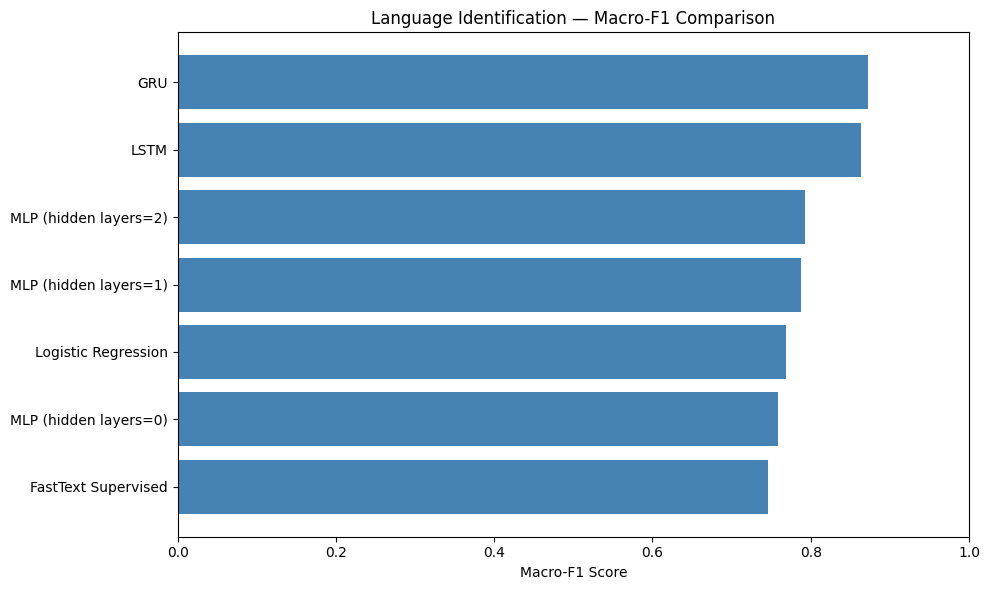

In [ ]:
results_df = pd.DataFrame(list(results.items()), columns=["Model", "Macro-F1"]).sort_values("Macro-F1", ascending=False)
print(results_df.to_string(index=False))
results_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison_macro_f1.csv"), index=False)

plt.figure(figsize=(10, 6))
plt.barh(results_df["Model"], results_df["Macro-F1"], color="steelblue")
plt.xlabel("Macro-F1 Score")
plt.title("Language Identification — Macro-F1 Comparison")
plt.gca().invert_yaxis()
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "model_comparison_macro_f1.png"), dpi=150)
plt.show()
